In [1]:
# Importing dataset using pandas  
import pandas as pd
 
# To do numerical operations    
import numpy as np

# Setting directory using os
import os

import warnings
warnings.filterwarnings("ignore")

# Set the display format to avoid scientific notation
pd.set_option('display.float_format', lambda x: '%.3f' % x)

In [2]:
# Importing dataset
data = pd.read_csv('Housing.csv')
data

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [3]:
# Checking the distribution of the variables
data.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,545.000,545.000,545.000,545.000,545.000,545.000
mean,4766729.248,5150.541,2.965,1.286,1.806,0.694
std,1870439.616,2170.141,0.738,0.502,0.867,0.862
min,1750000.000,1650.000,1.000,1.000,1.000,0.000
25%,3430000.000,3600.000,2.000,1.000,1.000,0.000
50%,4340000.000,4600.000,3.000,1.000,2.000,0.000
75%,5740000.000,6360.000,3.000,2.000,2.000,1.000
max,13300000.000,16200.000,6.000,4.000,4.000,3.000


In [4]:
# Checking the distribution of the categorical variables
data.describe(include='object')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


In [5]:
# To know the information of the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


### Data Pre-processing

In [6]:
# Checking for null values
data.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [7]:
# Checking for duplicates
len(data[data.duplicated()])

0

In [8]:
# Importing libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

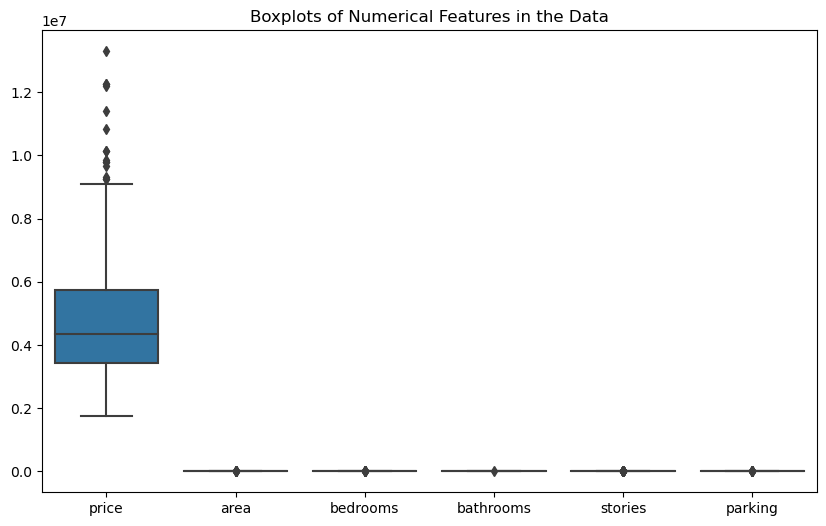

In [9]:
# Boxplots of Numerical Features in the Data to check the presence of outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=data)
plt.title('Boxplots of Numerical Features in the Data')
plt.show()

In [10]:
# Treating the outliers
def capping_outliers(data, column, threshold=1.5):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - threshold * IQR
    upper_bound = Q3 + threshold * IQR
    return data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]


In [11]:
# Treating the outliers in price
data = capping_outliers(data, 'price')

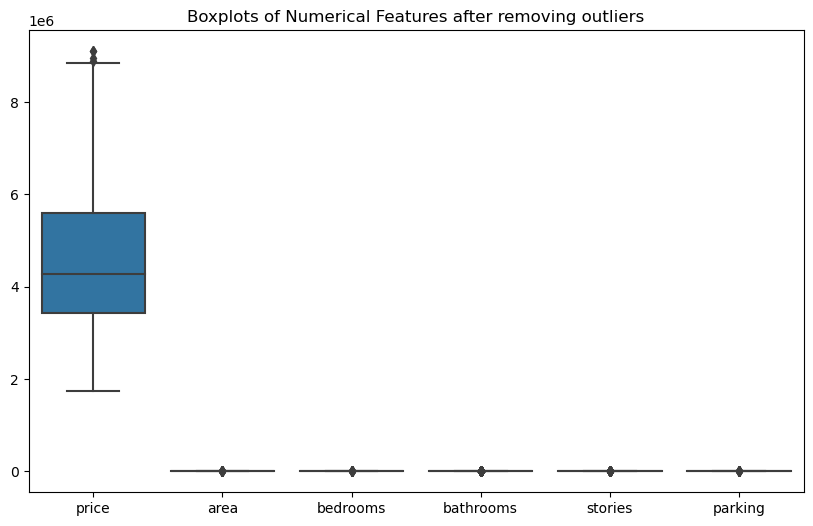

In [12]:
# Boxplots of Numerical Features after removing outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=data)
plt.title('Boxplots of Numerical Features after removing outliers')
plt.show()

In [13]:
# Treating the outliers in price
data = capping_outliers(data, 'price')

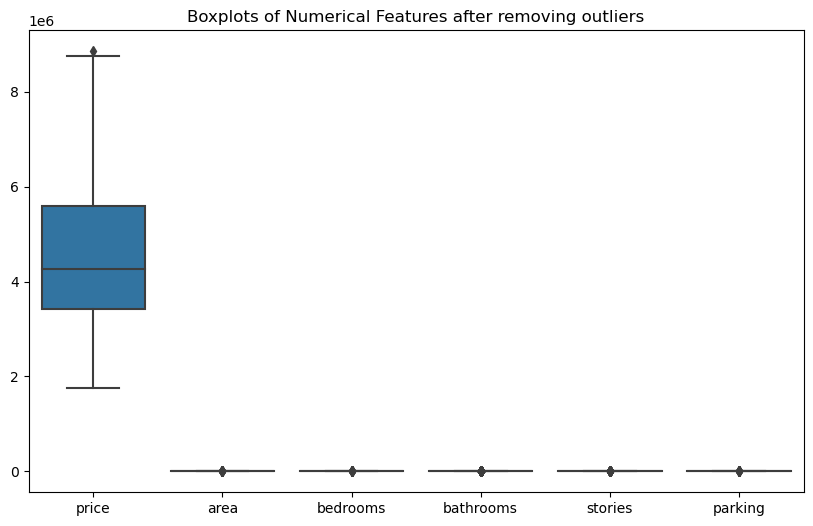

In [14]:
# Boxplots of Numerical Features after removing outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=data)
plt.title('Boxplots of Numerical Features after removing outliers')
plt.show()

### Exploratory Data Analysis

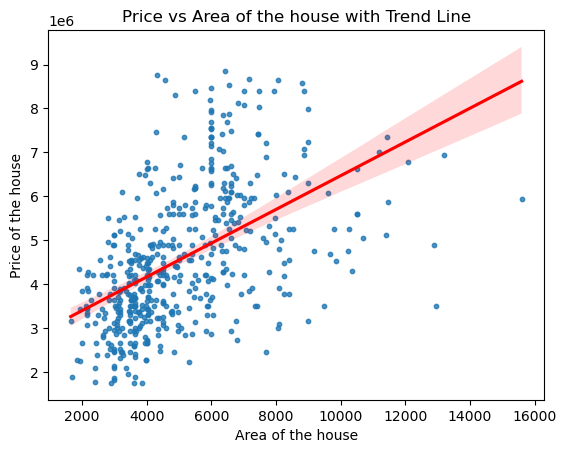

In [15]:
# price vs area of the house
sns.regplot(data=data, x='area', y='price', scatter_kws={'s': 10}, line_kws={'color': 'red'})
plt.xlabel('Area of the house')
plt.ylabel('Price of the house')
plt.title('Price vs Area of the house with Trend Line')
plt.show()

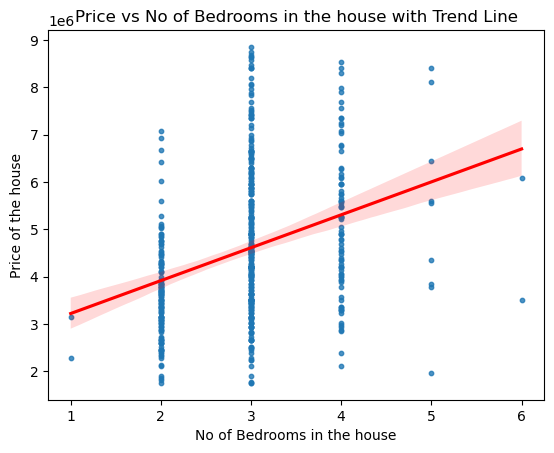

In [16]:
# price vs no of bedrooms of the house
sns.regplot(data=data, x='bedrooms', y='price', scatter_kws={'s': 10}, line_kws={'color': 'red'})
plt.xlabel('No of Bedrooms in the house')
plt.ylabel('Price of the house')
plt.title('Price vs No of Bedrooms in the house with Trend Line')
plt.show()

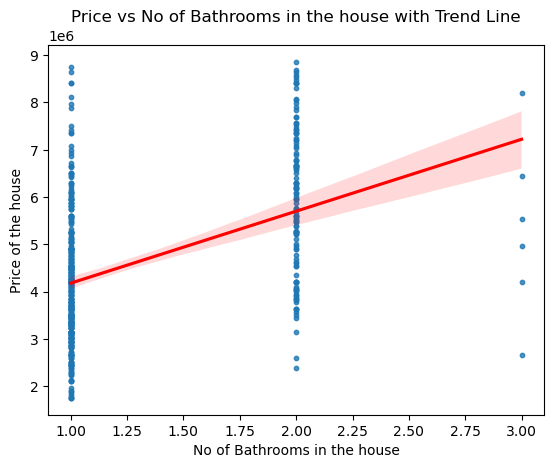

In [17]:
# price vs no of bathrooms of the house
sns.regplot(data=data, x='bathrooms', y='price', scatter_kws={'s': 10}, line_kws={'color': 'red'})
plt.xlabel('No of Bathrooms in the house')
plt.ylabel('Price of the house')
plt.title('Price vs No of Bathrooms in the house with Trend Line')
plt.show()

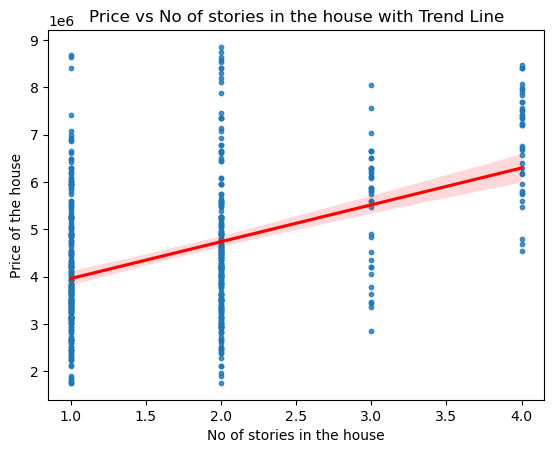

In [18]:
# price vs no of stories of the house
sns.regplot(data=data, x='stories', y='price', scatter_kws={'s': 10}, line_kws={'color': 'red'})
plt.xlabel('No of stories in the house')
plt.ylabel('Price of the house')
plt.title('Price vs No of stories in the house with Trend Line')
plt.show()

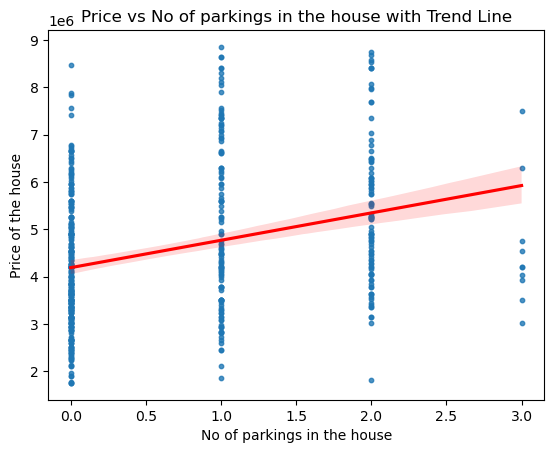

In [19]:
# price vs no of parkings of the house
sns.regplot(data=data, x='parking', y='price', scatter_kws={'s': 10}, line_kws={'color': 'red'})
plt.xlabel('No of parkings in the house')
plt.ylabel('Price of the house')
plt.title('Price vs No of parkings in the house with Trend Line')
plt.show()

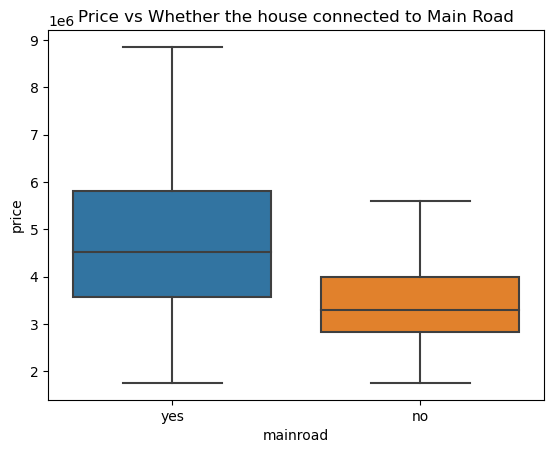

In [20]:
# price vs whether connected to main road
sns.boxplot(x=data['mainroad'],y =data['price'])
plt.title('Price vs Whether the house connected to Main Road')
plt.show()

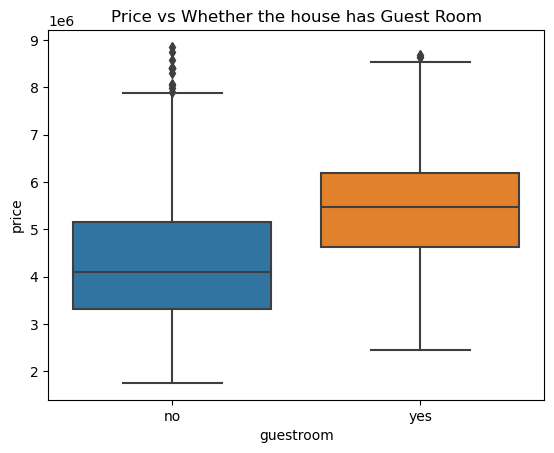

In [21]:
# price vs whether the house has a guest room
sns.boxplot(x=data['guestroom'],y =data['price'])
plt.title('Price vs Whether the house has Guest Room')
plt.show()

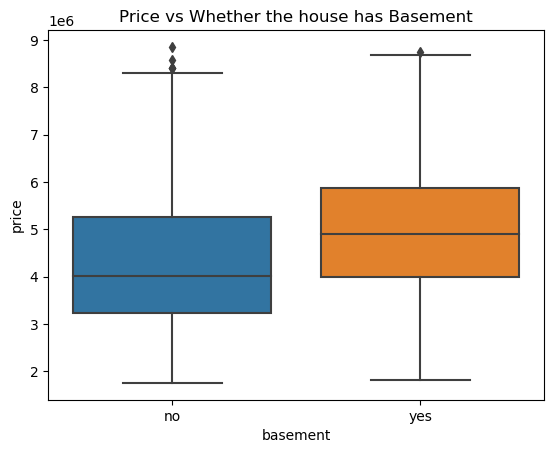

In [22]:
# price vs whether the house has a basement
sns.boxplot(x=data['basement'],y =data['price'])
plt.title('Price vs Whether the house has Basement')
plt.show()

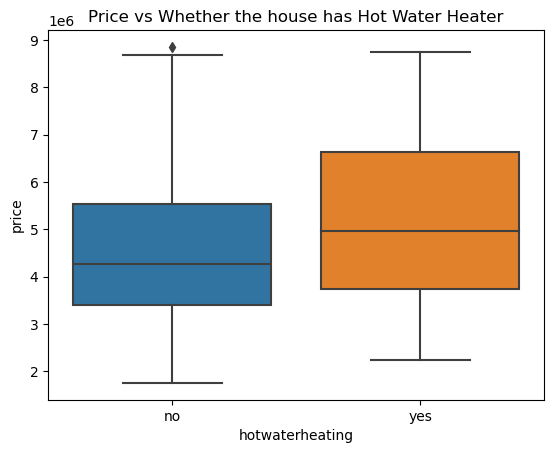

In [23]:
# price vs whether the house has a hot water heater
sns.boxplot(x=data['hotwaterheating'],y =data['price'])
plt.title('Price vs Whether the house has Hot Water Heater')
plt.show()

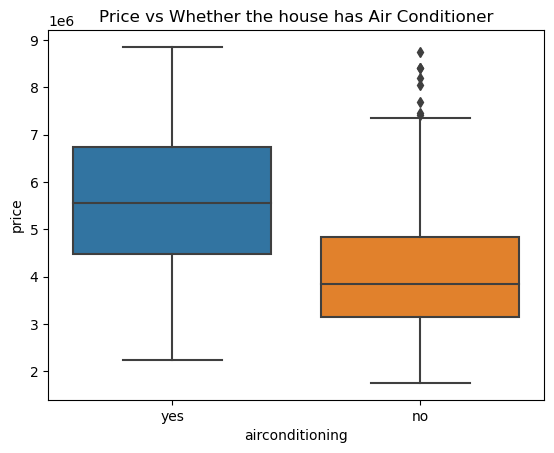

In [24]:
# price vs whether the house has a air conditioner
sns.boxplot(x=data['airconditioning'],y =data['price'])
plt.title('Price vs Whether the house has Air Conditioner')
plt.show()

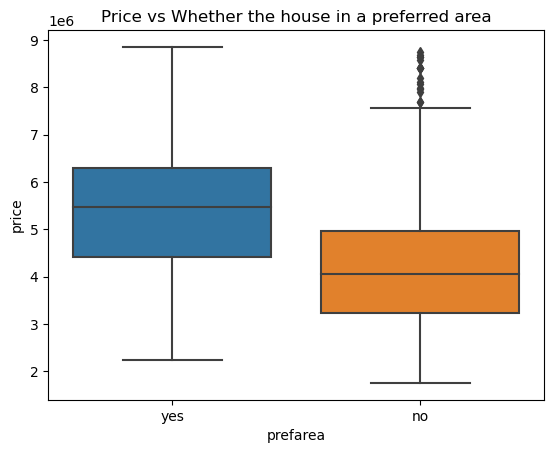

In [25]:
# price vs whether the house in a preferred area
sns.boxplot(x=data['prefarea'],y =data['price'])
plt.title('Price vs Whether the house in a preferred area')
plt.show()

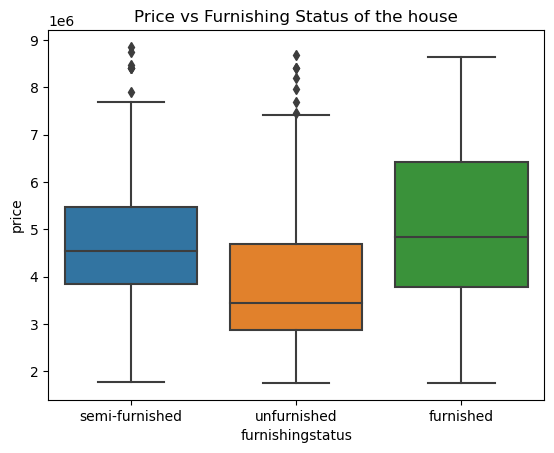

In [26]:
# price vs furnishing status of the house
sns.boxplot(x=data['furnishingstatus'],y =data['price'])
plt.title('Price vs Furnishing Status of the house')
plt.show()

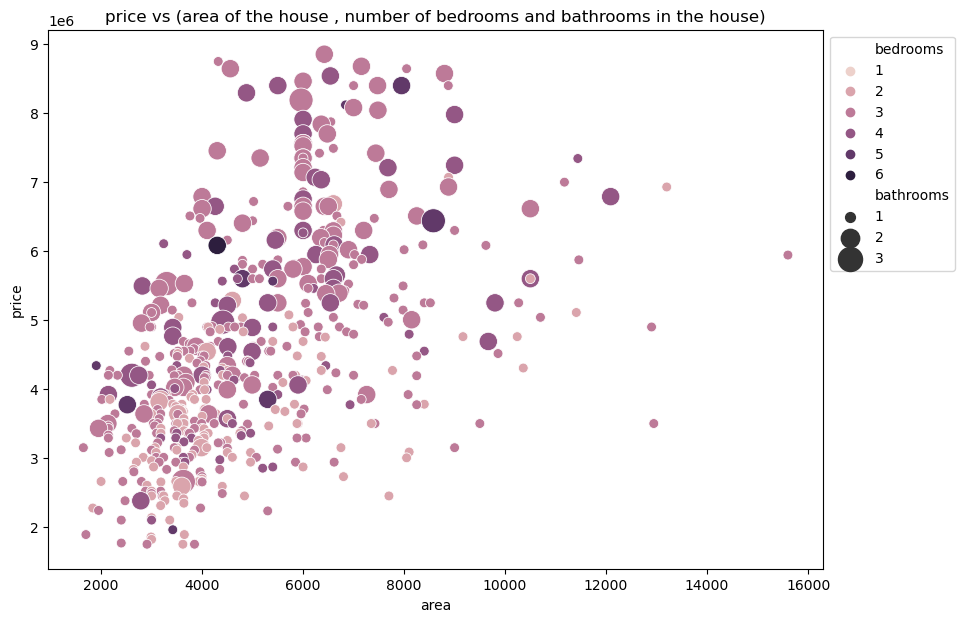

In [27]:
# price vs (area, bedrooms, bathrooms)
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(y="price", x="area", hue="bedrooms", size="bathrooms", data=data, ax=ax, sizes=(50, 300))
ax.set_title("price vs (area of the house , number of bedrooms and bathrooms in the house)")
ax.legend(loc="upper left", bbox_to_anchor=(1,1))
plt.show()

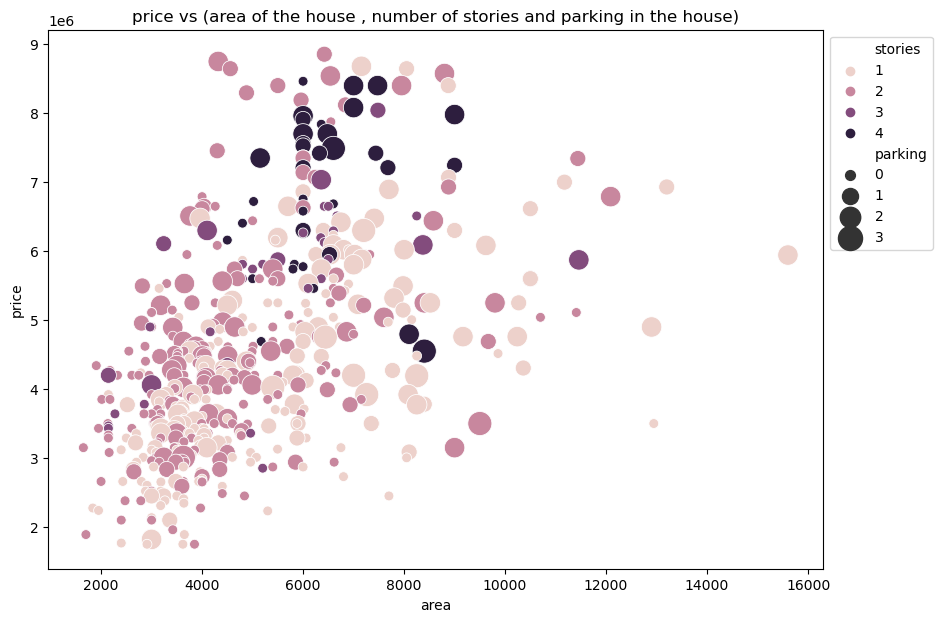

In [28]:
# price vs (area, stories, parking)
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(y="price", x="area", hue="stories", size="parking", data=data, ax=ax, sizes=(50, 300))
ax.set_title("price vs (area of the house , number of stories and parking in the house)")
ax.legend(loc="upper left", bbox_to_anchor=(1,1))
plt.show()

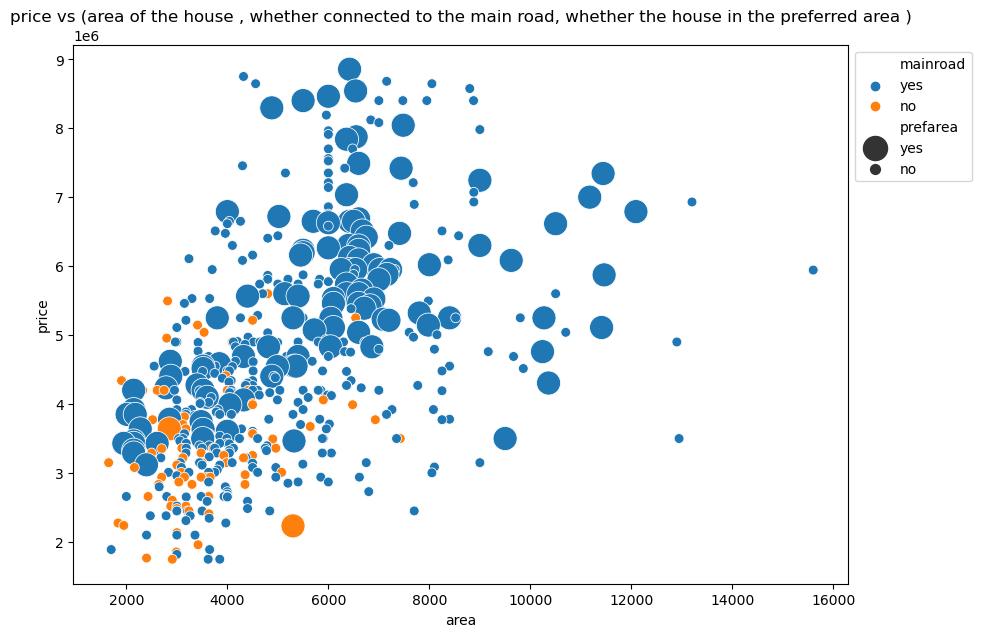

In [29]:
# price vs (area, main road, preferred area)
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(y="price", x="area", hue="mainroad", size="prefarea", data=data, ax=ax, sizes=(50, 300))
ax.set_title("price vs (area of the house , whether connected to the main road, whether the house in the preferred area )")
ax.legend(loc="upper left", bbox_to_anchor=(1,1))
plt.show()

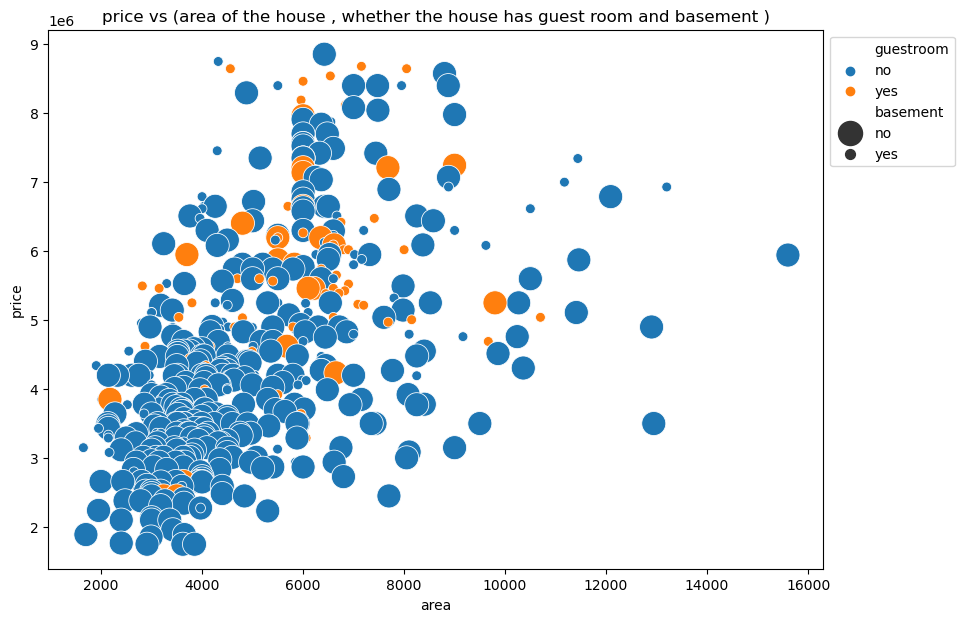

In [30]:
# price vs (area, guest room, basement)
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(y="price", x="area", hue="guestroom", size="basement", data=data, ax=ax, sizes=(50, 300))
ax.set_title("price vs (area of the house , whether the house has guest room and basement )")
ax.legend(loc="upper left", bbox_to_anchor=(1,1))
plt.show()

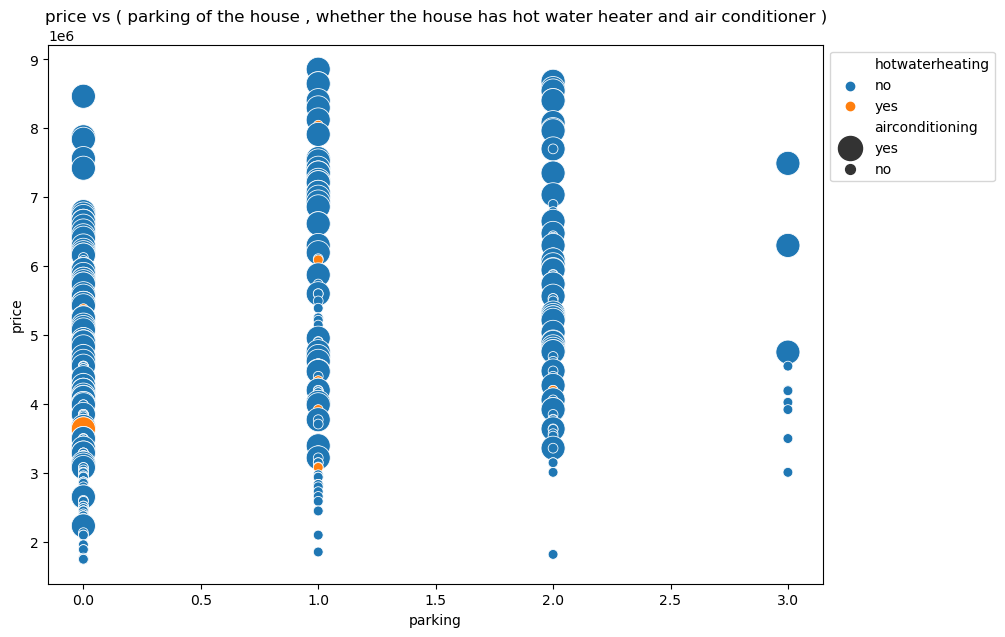

In [31]:
# price vs (parking,hot water heater, air conditioner)
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(y="price", x="parking", hue="hotwaterheating", size="airconditioning", data=data, ax=ax, sizes=(50, 300))
ax.set_title("price vs ( parking of the house , whether the house has hot water heater and air conditioner )")
ax.legend(loc="upper left", bbox_to_anchor=(1,1))
plt.show()

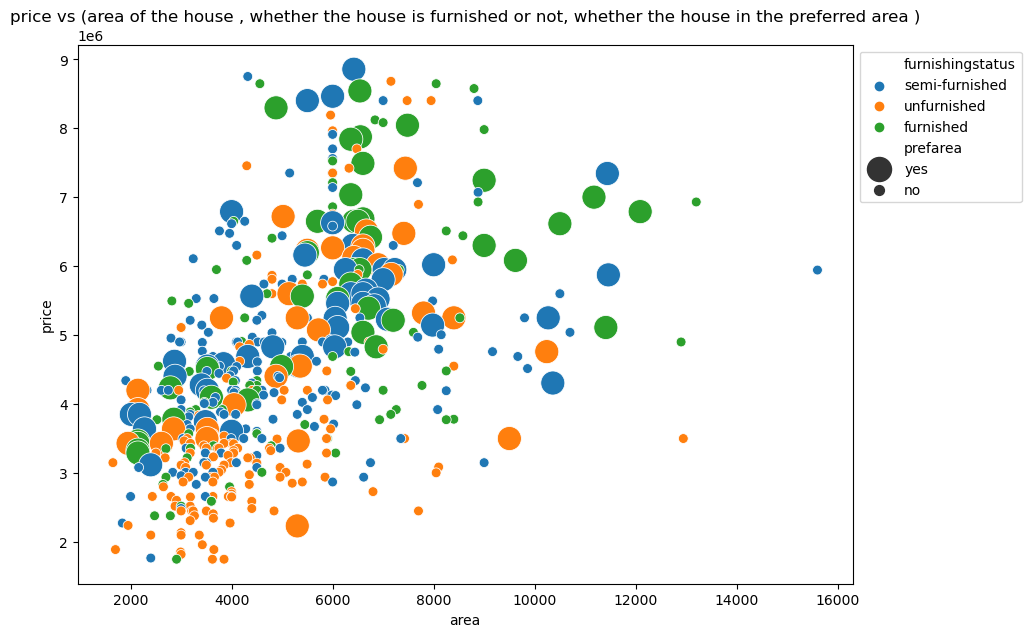

In [32]:
# price vs (area, furnishing status, preferred area)
fig, ax = plt.subplots(figsize=(10,7))
sns.scatterplot(y="price", x="area", hue="furnishingstatus", size="prefarea", data=data, ax=ax, sizes=(50, 300))
ax.set_title("price vs (area of the house , whether the house is furnished or not, whether the house in the preferred area )")
ax.legend(loc="upper left", bbox_to_anchor=(1,1))
plt.show()

In [33]:
# Converting the categorical variables from character to numerical 
from sklearn.preprocessing import LabelEncoder,StandardScaler
df = data.copy()
cols=['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
for label in cols:
    df[label]=LabelEncoder().fit_transform(df[label])
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
19,8855000,6420,3,2,2,1,0,0,0,1,1,1,1
20,8750000,4320,3,1,2,1,0,1,1,0,2,0,1
21,8680000,7155,3,2,1,1,1,1,0,1,2,0,2
22,8645000,8050,3,1,1,1,1,1,0,1,1,0,0
23,8645000,4560,3,2,2,1,1,1,0,1,1,0,0


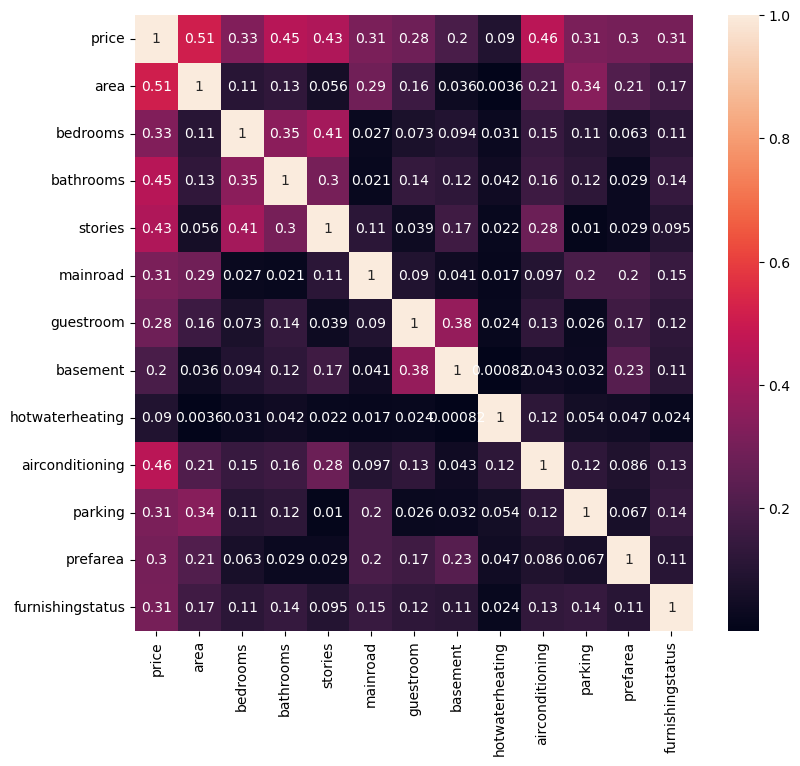

In [34]:
# heatmap for better inference
plt.figure(figsize=(9,8))
sns.heatmap(np.abs(df.corr()),annot= True)
plt.show()

In [35]:
df.corr()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
price,1.000,0.513,0.327,0.453,0.431,0.311,0.283,0.195,0.090,0.459,0.313,0.301,-0.305
area,0.513,1.000,0.109,0.129,0.056,0.288,0.157,0.036,0.004,0.208,0.342,0.214,-0.169
bedrooms,0.327,0.109,1.000,0.351,0.407,-0.027,0.073,0.094,0.031,0.146,0.105,0.063,-0.115
bathrooms,0.453,0.129,0.351,1.000,0.303,0.021,0.138,0.124,0.042,0.163,0.120,0.029,-0.143
stories,0.431,0.056,0.407,0.303,1.000,0.115,0.039,-0.166,0.022,0.277,0.010,0.029,-0.095
mainroad,0.311,0.288,-0.027,0.021,0.115,1.000,0.090,0.041,-0.017,0.097,0.195,0.196,-0.153
guestroom,0.283,0.157,0.073,0.138,0.039,0.090,1.000,0.375,-0.024,0.126,0.026,0.166,-0.123
basement,0.195,0.036,0.094,0.124,-0.166,0.041,0.375,1.000,0.001,0.043,0.032,0.226,-0.112
hotwaterheating,0.090,0.004,0.031,0.042,0.022,-0.017,-0.024,0.001,1.000,-0.121,0.054,-0.047,-0.024
airconditioning,0.459,0.208,0.146,0.163,0.277,0.097,0.126,0.043,-0.121,1.000,0.122,0.086,-0.133


In [36]:
df.shape

(526, 13)

In [37]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
19,8855000,6420,3,2,2,1,0,0,0,1,1,1,1
20,8750000,4320,3,1,2,1,0,1,1,0,2,0,1
21,8680000,7155,3,2,1,1,1,1,0,1,2,0,2
22,8645000,8050,3,1,1,1,1,1,0,1,1,0,0
23,8645000,4560,3,2,2,1,1,1,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,0,2,0,2
541,1767150,2400,3,1,1,0,0,0,0,0,0,0,1
542,1750000,3620,2,1,1,1,0,0,0,0,0,0,2
543,1750000,2910,3,1,1,0,0,0,0,0,0,0,0


### Model Building and Evaluation

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor, Booster, DMatrix
from sklearn import metrics
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from scipy.stats import randint
import joblib

In [39]:
# Split the Data
X = df.drop(['price', 'basement', 'hotwaterheating'], axis=1)
y = df['price']
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)

In [40]:
model_params = {
    'Linear Regression': {
        'model': LinearRegression(),
        'params': {}
    },
    'Random Forest Regressor': {
        'model': RandomForestRegressor(),
        'params': {
            'n_estimators': [int(x) for x in np.linspace(start=200, stop=2000, num=10)],
            'max_features': ['sqrt'],
            'max_depth': [int(x) for x in np.linspace(10, 110, num=11)],
            'min_samples_split': randint(2, 10),
            'min_samples_leaf': randint(1, 4),
            'bootstrap': [True, False]
        }
    },
    'XGB Regressor': {
        'model': XGBRegressor(),
        'params': {
            'n_estimators': [int(x) for x in np.linspace(start=100, stop=1000, num=50)],
            'max_depth': [int(x) for x in np.linspace(start=1, stop=15, num=1)],
            'learning_rate': [0.025, 0.05, 0.1, 0.15, 0.20],
            'min_child_weight': [int(x) for x in np.linspace(start=1, stop=10, num=1)],
            'gamma': [0, 0.1, 0.2, 0.3, 0.4, 0.5],
            'colsample_bytree': [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.8, 0.9],
            'reg_alpha': [0, 0.5, 1, 5],
            'reg_lambda': [0, 0.5, 1, 5]
        }
    }
}


In [41]:
import time

# Lists to store model performance metrics
r2_list = []
mse_list = []
score = []

# Loop through the model parameters
for i, (model_name, mp) in enumerate(model_params.items(), 1):
    start_time = time.time()  # Record the start time

    # Creating the model
    reg = RandomizedSearchCV(mp['model'], mp['params'], n_iter=100, cv=5, verbose=1, n_jobs=-1, return_train_score=False)

    # Fitting the train dataset into the model
    reg.fit(x_train, y_train)

    # Predict the test data set using the trained model
    y_pred = reg.predict(x_test)

    # Finding the R-squared and MSE of the model
    r2_list.append(r2_score(y_test, y_pred))
    mse_list.append(mean_squared_error(y_test, y_pred))

    # Record the end time
    end_time = time.time()

    # Calculate the elapsed time
    elapsed_time = end_time - start_time

    score.append({
        'Model': model_name,
        'Best Score': reg.best_score_,
        'Best Params': reg.best_params_,
        'Elapsed Time': elapsed_time  # Include elapsed time in the results
    })

    print(f"Model {i}/{len(model_params)} ({model_name}) completed in {elapsed_time:.2f} seconds.")


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Model 1/3 (Linear Regression) completed in 9.60 seconds.
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Model 2/3 (Random Forest Regressor) completed in 188.86 seconds.
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Model 3/3 (XGB Regressor) completed in 11.91 seconds.


In [42]:
# Model Comparison
pd.set_option("display.max_colwidth", None)
scores = pd.DataFrame(score, columns=['Model', 'Best Score', 'Best Params'])
regression_metrics = pd.DataFrame({'R-squared': r2_list, 'MSE': mse_list})

# Concatenate both the dataframes
result = pd.concat([scores, regression_metrics], axis=1, join='inner')

# Sort Best Score in descending order
result.sort_values(by=['Best Score'], inplace=True, ascending=False)

result

,Model,Best Score,Best Params,R-squared,MSE
2,XGB Regressor,0.631,"{'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estimators': 155, 'min_child_weight': 1, 'max_depth': 1, 'learning_rate': 0.15, 'gamma': 0.4, 'colsample_bytree': 0.1}",0.692,675926616039.665
1,Random Forest Regressor,0.608,"{'bootstrap': True, 'max_depth': 40, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 9, 'n_estimators': 600}",0.697,664904380498.347
0,Linear Regression,0.599,{},0.701,656833079920.718


* From the above 3 models created , i got good accuracy score in XGB Regressor model compared to other models

In [43]:
# Define the XGB Regressor with the specified parameters
xgb_model = XGBRegressor(
    reg_lambda=1,
    reg_alpha=0,
    n_estimators=724,
    min_child_weight=1,
    max_depth=1,
    learning_rate=0.025,
    gamma=0,
    colsample_bytree=0
)

# Fit the model on the training data
xgb_model.fit(x_train, y_train)

# Evaluate the model on testing data
testing_score = round(xgb_model.score(x_test, y_test) * 100, 3)

# Make predictions on the testing data
y_pred = xgb_model.predict(x_test)

# Calculate R-squared and MSE
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

# Print the results
print("The testing score is", testing_score)
print("R-squared: {:.3f}".format(r2))
print("MSE: {:.3f}".format(mse))


# Save the model using Booster
xgb_model.save_model('xgb_model.txt')
print("Model is Saved")

The testing score is 71.196
R-squared: 0.712
MSE: 632723209589.171
Model is Saved


In [44]:
#accuracy score of model 1
score1 = r2_score(y_test,y_pred)
score1

0.7119568701218253

In [45]:
df = pd.DataFrame({'Actual':y_test,'Predicted':y_pred,'variance':y_test-y_pred})
df.head()

,Actual,Predicted,variance
46,7525000,7464527.000,60473.000
290,4200000,3781372.750,418627.250
291,4200000,3868780.250,331219.750
397,3500000,4061401.500,-561401.500
437,3290000,4213609.500,-923609.500


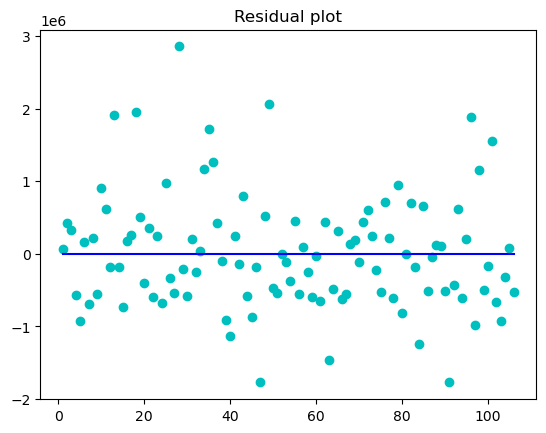

In [46]:
#residuals
residue = (y_test,y_pred)

#residual plot
x=[i for i in range(1,len(y_pred)+1)]
x_plot = plt.scatter(x,(y_test-y_pred),c='c')
plt.plot(x,[0]*len(y_pred),c='b')
plt.title("Residual plot")
plt.show()


### Prediction by getting new inputs

In [47]:
# Load the model using Booster
xgb_model = Booster(model_file='xgb_model.txt')

# Example input for testing the model
test_input = pd.DataFrame({
    'area': [8000],
    'bedrooms': [3],
    'bathrooms': [2],
    'stories': [2],
    'mainroad': [1],
    'guestroom': [0],
    'airconditioning': [1],
    'parking': [2],
    'prefarea': [1],
    'furnishingstatus': [0]  # Assuming you want to keep one of the three categories (furnished, semi-furnished, unfurnished)
})

# Convert the input data to DMatrix
dtest = DMatrix(test_input)

# Predict using the loaded model
predicted_price = xgb_model.predict(dtest)

print(f"Predicted Price: {predicted_price}")

Predicted Price: [6847363.5]
